# Model mesh (delivered)

The mesh of this case was delivered (`inputs/delivery_2026-11-15/nc_mesh/`:
`build_nc_mesh.py` + `snapmesh.py`, DistMesh on a 3 arc-second DEM; settings and
statistics in `nc_out/nc_mesh_info.json`): 242,110 nodes, edges from about 80 m at
the shore to 3.9 km offshore, sounds closed, offshore flattened at about 100 m.
`inputs/GRID/NorthCarolina_mesh.nc` is that file (`nc_snapwave_net.nc`), unchanged.

This notebook only checks it: nothing is meshed here.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from bluemath_tk.topo_bathy.mesh import open_boundary_nodes, outline_rings, read_mesh
from utils.config import PATHS, SIMULATIONS, resolve

mesh = read_mesh(resolve(PATHS["mesh_file"]))
tri = mesh.triangles
scale = np.cos(np.radians(mesh.y.mean()))
edges = np.concatenate([tri[:, [0, 1]], tri[:, [1, 2]], tri[:, [2, 0]]])
length = np.hypot((mesh.x[edges[:, 0]] - mesh.x[edges[:, 1]]) * scale, mesh.y[edges[:, 0]] - mesh.y[edges[:, 1]]) * 111_195
print(f"nodes {mesh.x.size:,}  triangles {len(tri):,}  outlines {[len(r) for r in outline_rings(mesh)]}")
print(f"edge length (m): min {length.min():.0f}  median {np.median(length):.0f}  max {length.max():.0f}")
print(f"depth (m, positive down): {mesh.depth.min():.1f} to {mesh.depth.max():.1f}; dry nodes {int((mesh.depth <= 0).sum()):,}")

nodes 242,110  triangles 480,156  outlines [4062]
edge length (m): min 81  median 347  max 3872
depth (m, positive down): -17.0 to 111.1; dry nodes 25,375


## Depth and open boundary

The open boundary (red) is the outline through the delivered boundary points, out to
the coast (`simulations.snapwave.coast_depth`): the goals of notebook 04 go along it.

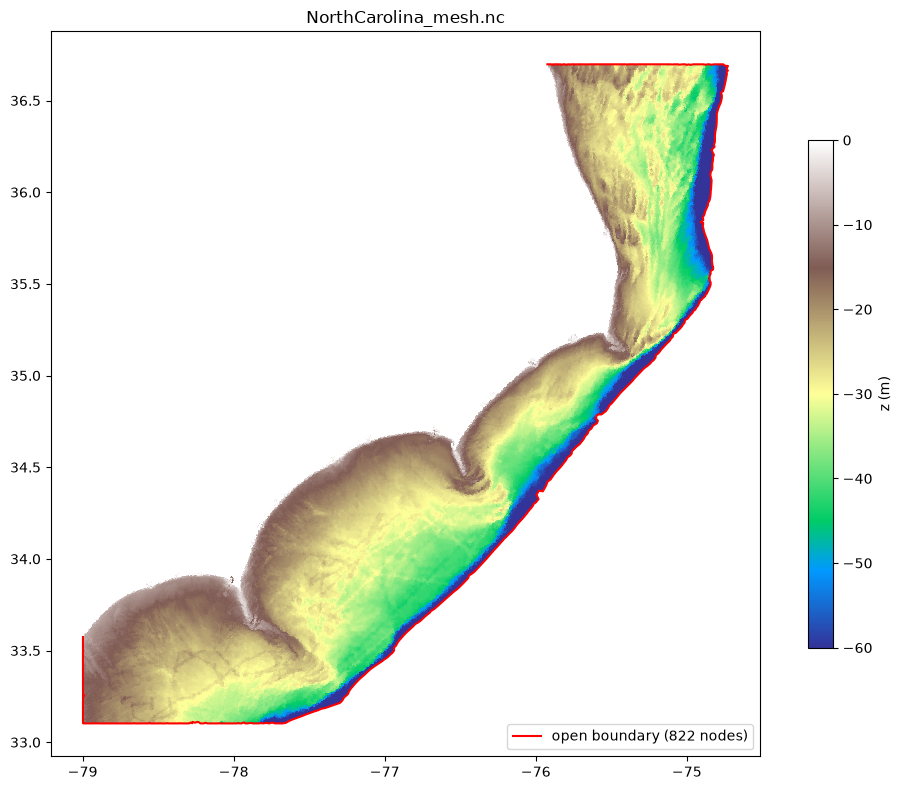

In [2]:
points = np.loadtxt(resolve("inputs/delivery_2026-11-15/nc_mesh/nc_out/nc_bndpoints.txt"))
open_nodes = open_boundary_nodes(mesh, points, coast_depth=SIMULATIONS["snapwave"]["coast_depth"])

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.tripcolor(mesh.triangulation(), -mesh.depth, vmin=-60, vmax=0, cmap="terrain", rasterized=True)
ax.plot(mesh.x[open_nodes], mesh.y[open_nodes], color="red", lw=1.5, label=f"open boundary ({len(open_nodes)} nodes)")
ax.set_aspect(1 / scale)
ax.legend(loc="lower right")
fig.colorbar(im, ax=ax, shrink=0.7, label="z (m)")
ax.set_title(resolve(PATHS["mesh_file"]).name)
fig.tight_layout()